# Combined model — test evaluation + prediction-outcome image gallery

Loads `checkpoints/combined_windowed_best_model.pt` (windowed model trained from scratch on
UniTalk-ASD + full AVA-ActiveSpeaker combined, F1=0.6932) and evaluates it on the held-out combined
test split (UniTalk-ASD `test_split.csv` + AVA `test_split.csv`).

Section 1 re-derives the exact same windows `scripts/modeling/evaluate/windowed_combined.py` scores — but
additionally keeps each window's source `image_name`s (which the production `WindowedLandmarkSequenceDataset`
discards once windowing is done), so a prediction can be traced back to an actual frame on disk. The
resulting metrics are cross-checked against `evaluation_windowed_combined/eval_metrics.json` to
confirm this reproduction is faithful before trusting anything built on top of it.

Section 2 shows metrics/charts (same suite `src/metrics.py` already provides).

Section 3 is the main ask: for each of the 4 outcome categories —
**correct SPEAKING** (TP), **missed SPEAKING** (FN, model said NOT_SPEAKING), **correct NOT_SPEAKING**
(TN), **false SPEAKING** (FP, model said SPEAKING) — 10 different people's representative frame,
shown both plain and with freshly re-detected (pixel-space, not the CSV's normalized) landmarks
overlaid, same fix as notebook 06.

In [1]:
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
sys.path.append(str(PROJECT_ROOT / "src"))
sys.path.append(str(PROJECT_ROOT / "scripts"))

from config import (
    AVA_PROCESSED_DATASET_DIR,
    AVA_RAW_CLIPS_VIDEOS_DIR,
    CHECKPOINTS_DIR,
    COMBINED_WINDOWED_BEST_CHECKPOINT_FILENAME,
    DATA_PROCESSED_DIR,
    MOUTH_LANDMARK_INDICES,
    RAW_CLIPS_VIDEOS_DIR,
    TEST_SPLIT_FILENAME,
    WINDOW_MIN_DETECTED_FRAMES_RATIO,
    WINDOW_PAD_SHORT_TRACKS,
    WINDOW_SIZE,
    WINDOW_STRIDE,
)
from dataset import FEATURE_COLUMNS, NUM_INPUT_FEATURES
from windowed_model import WindowedSpeakingDetectorRNN
from metrics import compute_metrics, format_report, plot_confusion_matrix, plot_pr_curve, plot_roc_curve
from extract_landmarks import PersonLandmarkExtractor

assert not WINDOW_PAD_SHORT_TRACKS, (
    "this notebook's windowing only replicates the drop-short-tracks path — "
    "config.WINDOW_PAD_SHORT_TRACKS is now True, update build_windows() before trusting results"
)

DATASET_SOURCES = [
    ("UniTalk-ASD", DATA_PROCESSED_DIR / "val" / TEST_SPLIT_FILENAME, RAW_CLIPS_VIDEOS_DIR, "val"),
    ("AVA-ActiveSpeaker", AVA_PROCESSED_DATASET_DIR / "val" / TEST_SPLIT_FILENAME, AVA_RAW_CLIPS_VIDEOS_DIR, "val"),
]

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = WindowedSpeakingDetectorRNN().to(device)
model.load_state_dict(torch.load(CHECKPOINTS_DIR / COMBINED_WINDOWED_BEST_CHECKPOINT_FILENAME, map_location=device))
model.eval()
print(f"loaded {CHECKPOINTS_DIR / COMBINED_WINDOWED_BEST_CHECKPOINT_FILENAME} on {device}")

loaded /data/bola/Train RNN ASD/checkpoints/combined_windowed_best_model.pt on cuda


## 1. Load test tracks and re-derive windows (with image-name tracking)

Mirrors `src/dataset.py`'s `LandmarkSequenceDataset` (same `MIN_DETECTED_FRAMES_RATIO` track filter)
and `src/windowed_dataset.py`'s `WindowedLandmarkSequenceDataset` (same non-overlapping
`window_size`/`window_stride`/`min_detected_ratio` for the test split), but additionally keeps
`image_name`/`video_id`/dataset-source/raw-dir alongside each window so a prediction can be traced
back to a file on disk — the one piece of information the production classes intentionally discard
once a window's feature array is built.

In [2]:
from config import MIN_DETECTED_FRAMES_RATIO


def load_tracks(csv_path: Path) -> pd.DataFrame:
    usecols = ["person_id", "video_id", "image_name", "detected", "target_index"] + FEATURE_COLUMNS
    df = pd.read_csv(csv_path, usecols=usecols, engine="pyarrow")
    df["frame_ts"] = df["image_name"].map(lambda s: float(Path(s).stem))
    df.sort_values(["person_id", "frame_ts"], inplace=True, kind="mergesort")
    return df


def build_windows(df: pd.DataFrame, dataset_label: str, raw_dir: Path, raw_split: str) -> list[dict]:
    windows = []
    n_track_rejected = n_window_dropped = 0
    for person_id, group in df.groupby("person_id", sort=False):
        detected = group["detected"].to_numpy()
        if detected.mean() < MIN_DETECTED_FRAMES_RATIO:
            n_track_rejected += 1
            continue

        feats = group[FEATURE_COLUMNS].to_numpy(dtype=np.float32, copy=True)
        feats[~detected] = 0.0
        labels = group["target_index"].to_numpy(dtype=np.int64, copy=True)
        video_id = group["video_id"].iloc[0]
        image_names = group["image_name"].to_numpy()
        track_len = feats.shape[0]

        if track_len < WINDOW_SIZE:
            n_window_dropped += 1
            continue

        for start in range(0, track_len - WINDOW_SIZE + 1, WINDOW_STRIDE):
            end = start + WINDOW_SIZE
            window_mask = detected[start:end]
            if window_mask.mean() < WINDOW_MIN_DETECTED_FRAMES_RATIO:
                n_window_dropped += 1
                continue
            window_labels = labels[start:end][window_mask]
            window_label = int(window_labels.mean() > 0.5)
            windows.append({
                "features": feats[start:end],
                "length": WINDOW_SIZE,
                "label": window_label,
                "person_id": person_id,
                "video_id": video_id,
                "image_names": image_names[start:end],
                "detected": window_mask,
                "dataset": dataset_label,
                "raw_dir": raw_dir,
                "raw_split": raw_split,
            })
    print(f"[{dataset_label}] {len(windows)} windows, {n_track_rejected} tracks rejected (detection), {n_window_dropped} windows/short-tracks dropped")
    return windows


all_windows = []
for name, csv_path, raw_dir, raw_split in DATASET_SOURCES:
    df = load_tracks(csv_path)
    all_windows.extend(build_windows(df, name, raw_dir, raw_split))
    del df

print(f"\ntotal: {len(all_windows)} windows")

[UniTalk-ASD] 2433 windows, 1745 tracks rejected (detection), 929 windows/short-tracks dropped


[AVA-ActiveSpeaker] 2305 windows, 844 tracks rejected (detection), 606 windows/short-tracks dropped

total: 4738 windows


## 2. Run the model and validate against the recorded evaluation

Batches through `all_windows` manually (no DataLoader needed — everything's already in memory) and
compares the resulting metrics against `evaluation_windowed_combined/eval_metrics.json` (the
already-recorded result from `scripts/modeling/evaluate/windowed_combined.py`) to confirm this notebook's
independently-rebuilt windows are a faithful match before trusting the image gallery built on top of
them.

In [3]:
BATCH_SIZE = 128


@torch.no_grad()
def predict_all(windows: list[dict]) -> np.ndarray:
    probs = np.zeros(len(windows), dtype=np.float64)
    for i in range(0, len(windows), BATCH_SIZE):
        batch = windows[i : i + BATCH_SIZE]
        features = torch.from_numpy(np.stack([w["features"] for w in batch])).to(device)
        lengths = torch.tensor([w["length"] for w in batch], dtype=torch.long)
        logits = model(features, lengths)
        probs[i : i + len(batch)] = torch.sigmoid(logits).cpu().numpy()
    return probs


y_prob = predict_all(all_windows)
y_true = np.array([w["label"] for w in all_windows], dtype=np.int64)
y_pred = (y_prob > 0.5).astype(np.int64)

for i, w in enumerate(all_windows):
    w["pred"] = int(y_pred[i])
    w["prob"] = float(y_prob[i])

metrics = compute_metrics(y_true, y_pred, y_prob)
print(format_report(metrics))

import json
with open(PROJECT_ROOT / "evaluation_windowed_combined" / "eval_metrics.json") as f:
    recorded = json.load(f)
print("\n--- cross-check against evaluate_windowed_combined.py's recorded result ---")
for key in ("n_samples", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"):
    match = "OK" if (key == "n_samples" and metrics[key] == recorded[key]) or (
        key != "n_samples" and abs(metrics[key] - recorded[key]) < 1e-4
    ) else "MISMATCH"
    print(f"  {key}: notebook={metrics[key]!r}  recorded={recorded[key]!r}  [{match}]")

n_samples=4738
accuracy=0.8487
precision=0.7350  recall=0.6559  f1=0.6932
roc_auc=0.8991  pr_auc=0.7878
confusion matrix (rows=true, cols=pred):
                    pred_NOT_SPEAKING     pred_SPEAKING_AUDIBLE
  true_NOT_SPEAKING         3211                  292
  true_SPEAKING_AUDIBLE        425                  810

--- cross-check against evaluate_windowed_combined.py's recorded result ---
  n_samples: notebook=4738  recorded=4738  [OK]
  accuracy: notebook=0.848670325031659  recorded=0.848670325031659  [OK]
  precision: notebook=0.73502722323049  recorded=0.73502722323049  [OK]
  recall: notebook=0.6558704453441295  recorded=0.6558704453441295  [OK]
  f1: notebook=0.693196405648267  recorded=0.693196405648267  [OK]
  roc_auc: notebook=0.8990706635492308  recorded=0.8990697389513442  [OK]
  pr_auc: notebook=0.7878179158881184  recorded=0.7878171053879096  [OK]


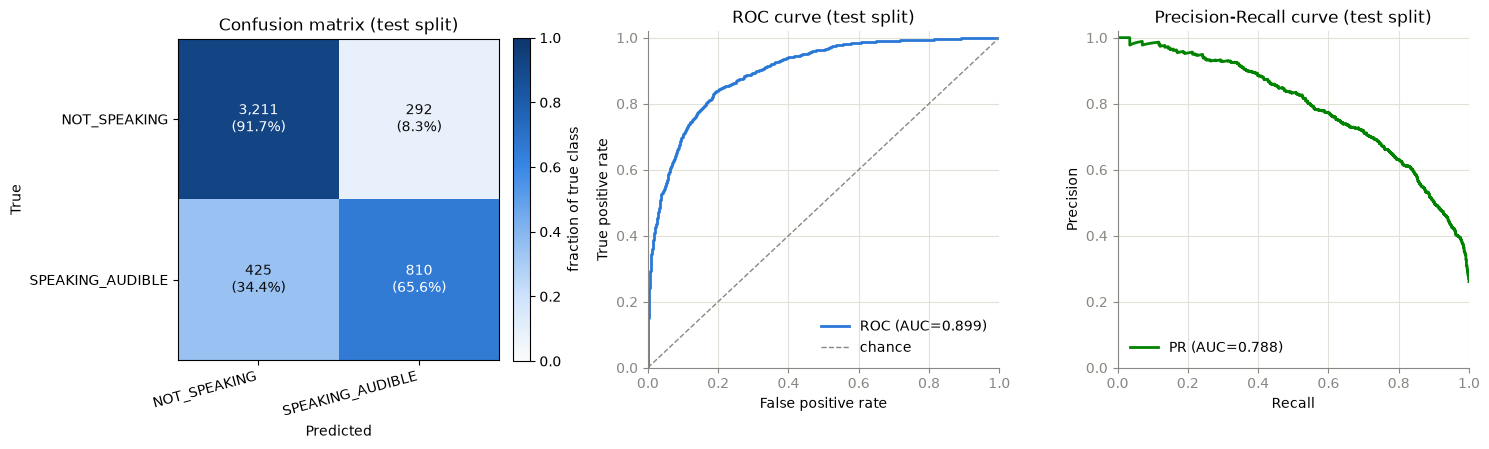

,n_windows,accuracy,speaking_frac
dataset,,,
AVA-ActiveSpeaker,2305,0.824729,0.314967
UniTalk-ASD,2433,0.871352,0.209207


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
plot_confusion_matrix(metrics, split="test", ax=axes[0])
plot_roc_curve(metrics, split="test", ax=axes[1])
plot_pr_curve(metrics, split="test", ax=axes[2])
fig.tight_layout()
plt.show()

per_dataset = pd.DataFrame([
    {"dataset": w["dataset"], "correct": w["pred"] == w["label"], "label": w["label"]}
    for w in all_windows
])
summary = per_dataset.groupby("dataset").agg(
    n_windows=("correct", "size"),
    accuracy=("correct", "mean"),
    speaking_frac=("label", "mean"),
)
summary

## 3. Sample images by prediction outcome — 10 different people per category

Four categories: **TP** (actually speaking, model got it right), **FN** (actually speaking, model
missed it — said not speaking), **TN** (actually not speaking, model got it right), **FP** (actually
not speaking, model wrongly said speaking). For each, up to 10 windows are sampled from 10 *different*
`person_id`s (fixed seed, shuffled — one window per person, never two samples from the same track).

For each sampled window, the representative frame is the one closest to the window's midpoint that
was actually `detected=True` (so there's something to draw landmarks on) — falls back to the plain
midpoint frame if the window has no detected frame at all (rare, since windows need ≥50% detected
frames to be kept in the first place). Landmarks are freshly re-detected on the real image
(`normalize=False`), same as notebook 06 — the CSV's stored landmark columns are normalized
(nose-tip-centered, interocular-scaled) and can't be drawn directly on the raw crop.

In [5]:
N_SAMPLES = 10
CATEGORIES = {
    "TP — correctly SPEAKING": lambda w: w["label"] == 1 and w["pred"] == 1,
    "FN — missed SPEAKING (model said NOT_SPEAKING)": lambda w: w["label"] == 1 and w["pred"] == 0,
    "TN — correctly NOT_SPEAKING": lambda w: w["label"] == 0 and w["pred"] == 0,
    "FP — falsely SPEAKING (model said SPEAKING)": lambda w: w["label"] == 0 and w["pred"] == 1,
}


def representative_frame_index(window: dict) -> int:
    mid = window["length"] // 2
    detected_idx = np.flatnonzero(window["detected"])
    if len(detected_idx) == 0:
        return mid
    return int(detected_idx[np.argmin(np.abs(detected_idx - mid))])


def sample_category(predicate, n: int, seed: int = 42) -> list[dict]:
    matches = [w for w in all_windows if predicate(w)]
    rng = random.Random(seed)
    rng.shuffle(matches)
    seen_people = set()
    sampled = []
    for w in matches:
        key = (w["dataset"], w["person_id"])
        if key in seen_people:
            continue
        seen_people.add(key)
        sampled.append(w)
        if len(sampled) >= n:
            break
    return sampled


category_samples = {label: sample_category(pred, N_SAMPLES) for label, pred in CATEGORIES.items()}
for label, samples in category_samples.items():
    print(f"{label}: {len(samples)}/{N_SAMPLES} sampled (from {sum(1 for w in all_windows if CATEGORIES[label](w))} matching windows)")

TP — correctly SPEAKING: 10/10 sampled (from 810 matching windows)
FN — missed SPEAKING (model said NOT_SPEAKING): 10/10 sampled (from 425 matching windows)
TN — correctly NOT_SPEAKING: 10/10 sampled (from 3211 matching windows)
FP — falsely SPEAKING (model said SPEAKING): 10/10 sampled (from 292 matching windows)


W0000 00:00:1784402486.710565  735952 face_landmarker_graph.cc:174] Sets FaceBlendshapesGraph acceleration to xnnpack by default.
I0000 00:00:1784402486.778711  735952 gl_context_egl.cc:85] Successfully initialized EGL. Major : 1 Minor: 5
I0000 00:00:1784402486.849232  736003 gl_context.cc:385] GL version: 3.2 (OpenGL ES 3.2 NVIDIA 580.159.03), renderer: NVIDIA RTX PRO 6000 Blackwell Server Edition/PCIe/SSE2


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
E0000 00:00:1784402487.172933  736003 tensor.cc:404] Tensors are designed for single writes. Multiple writes to a Tensor instance are not supported and may lead to undefined behavior due to lack of synchronization.


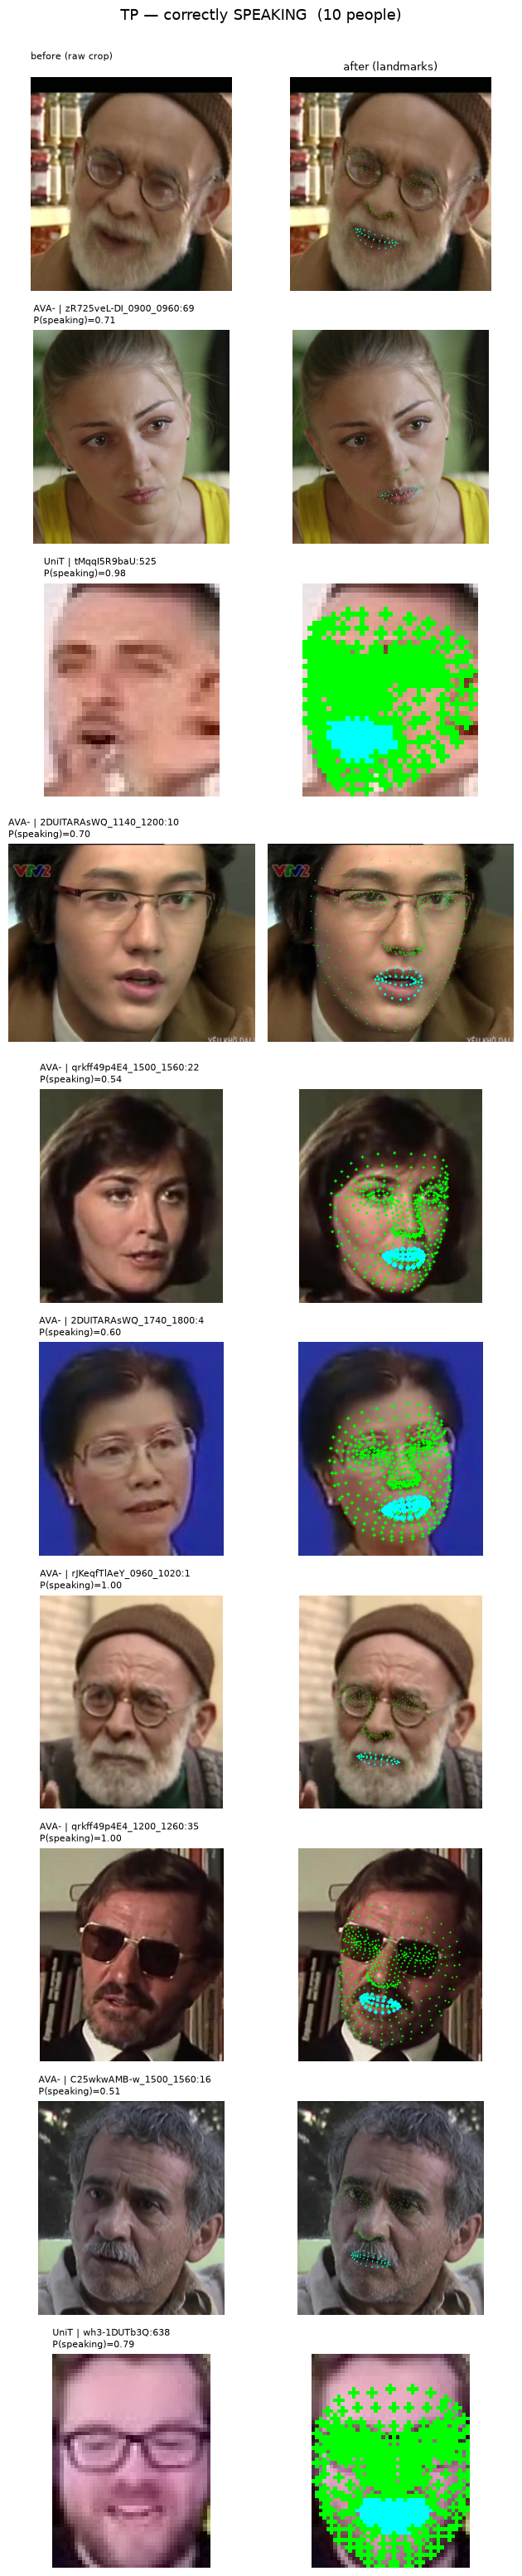

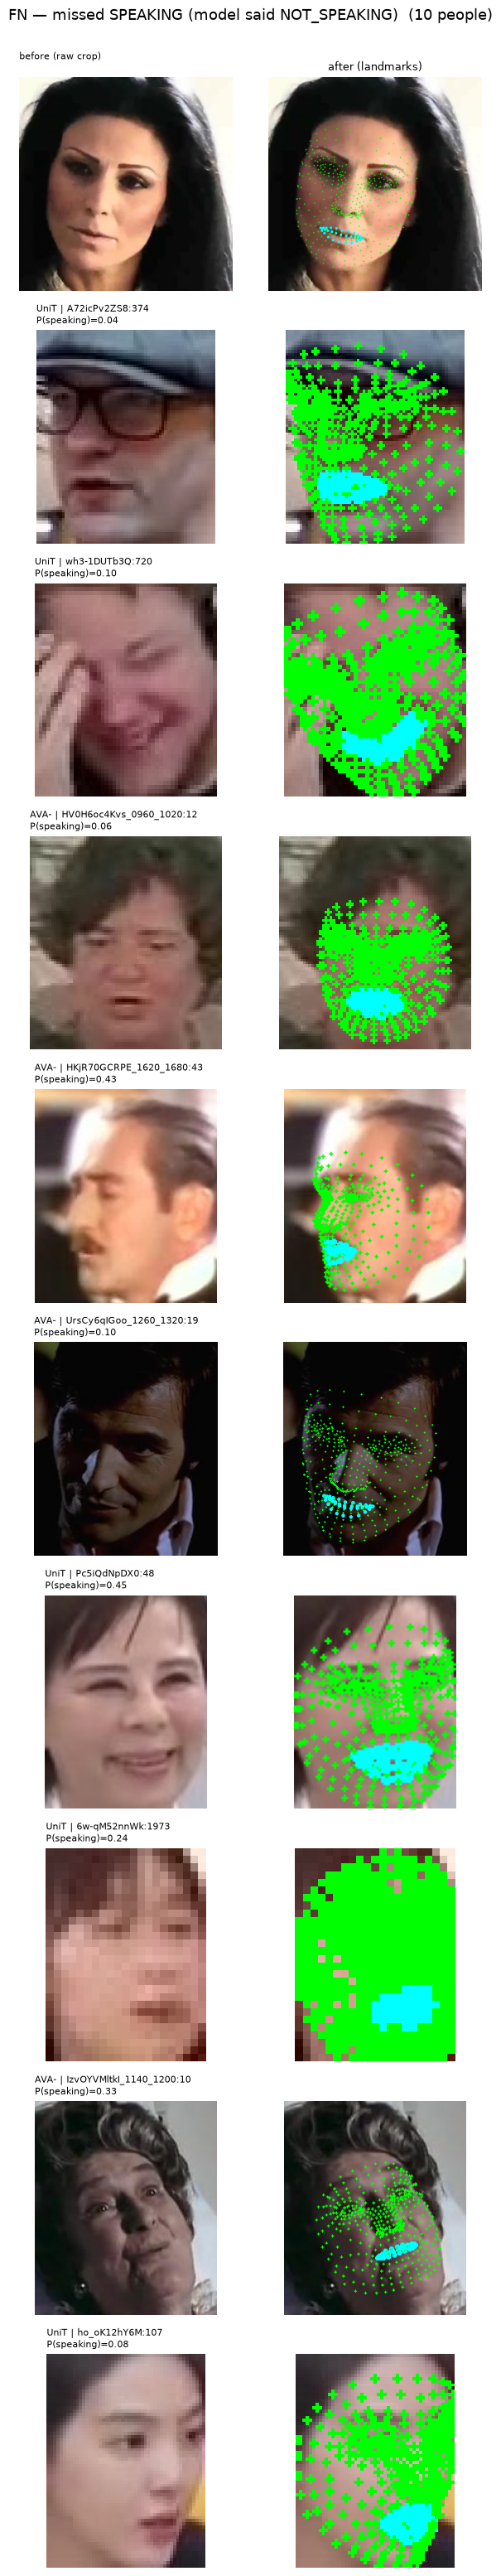

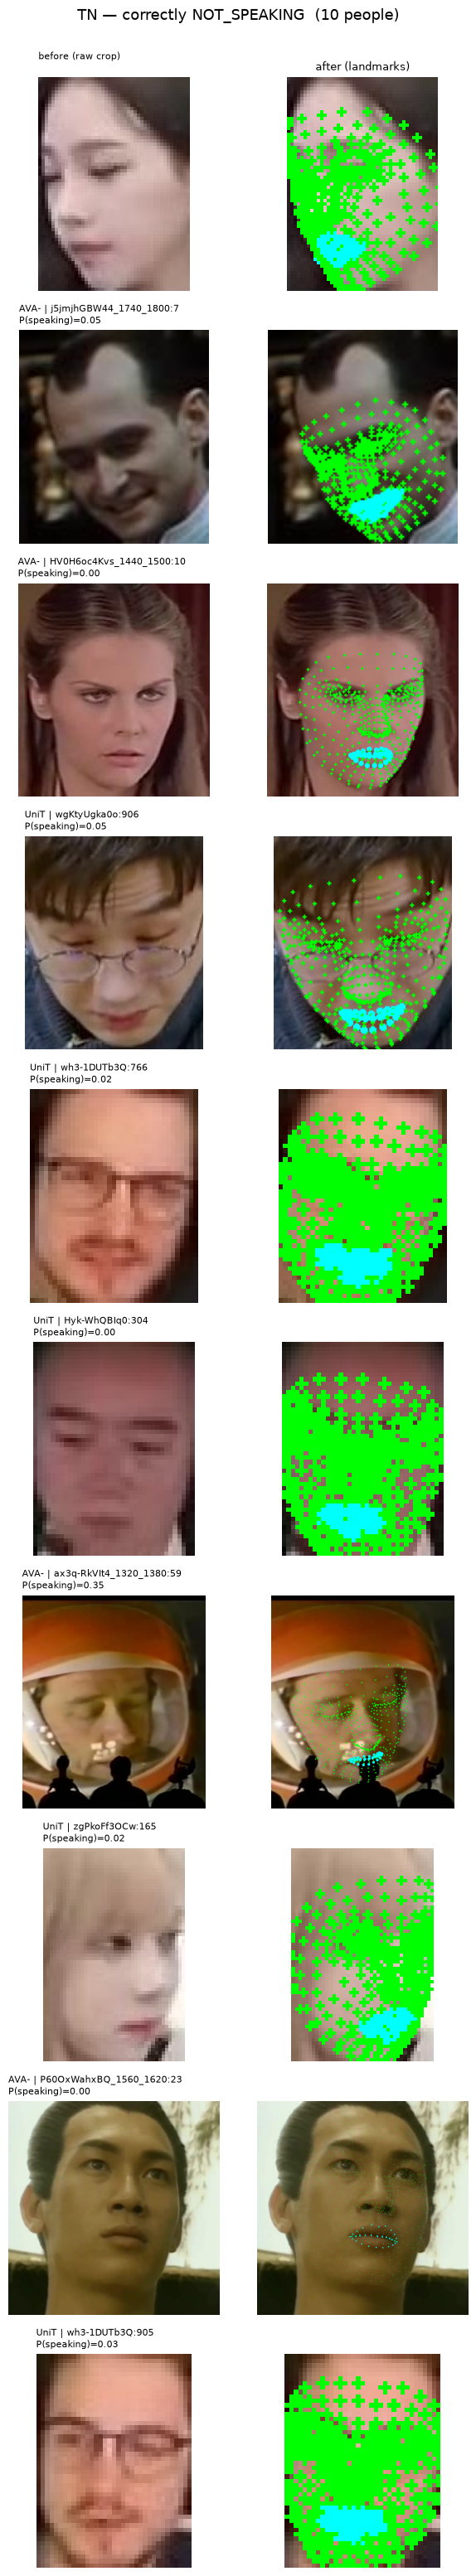

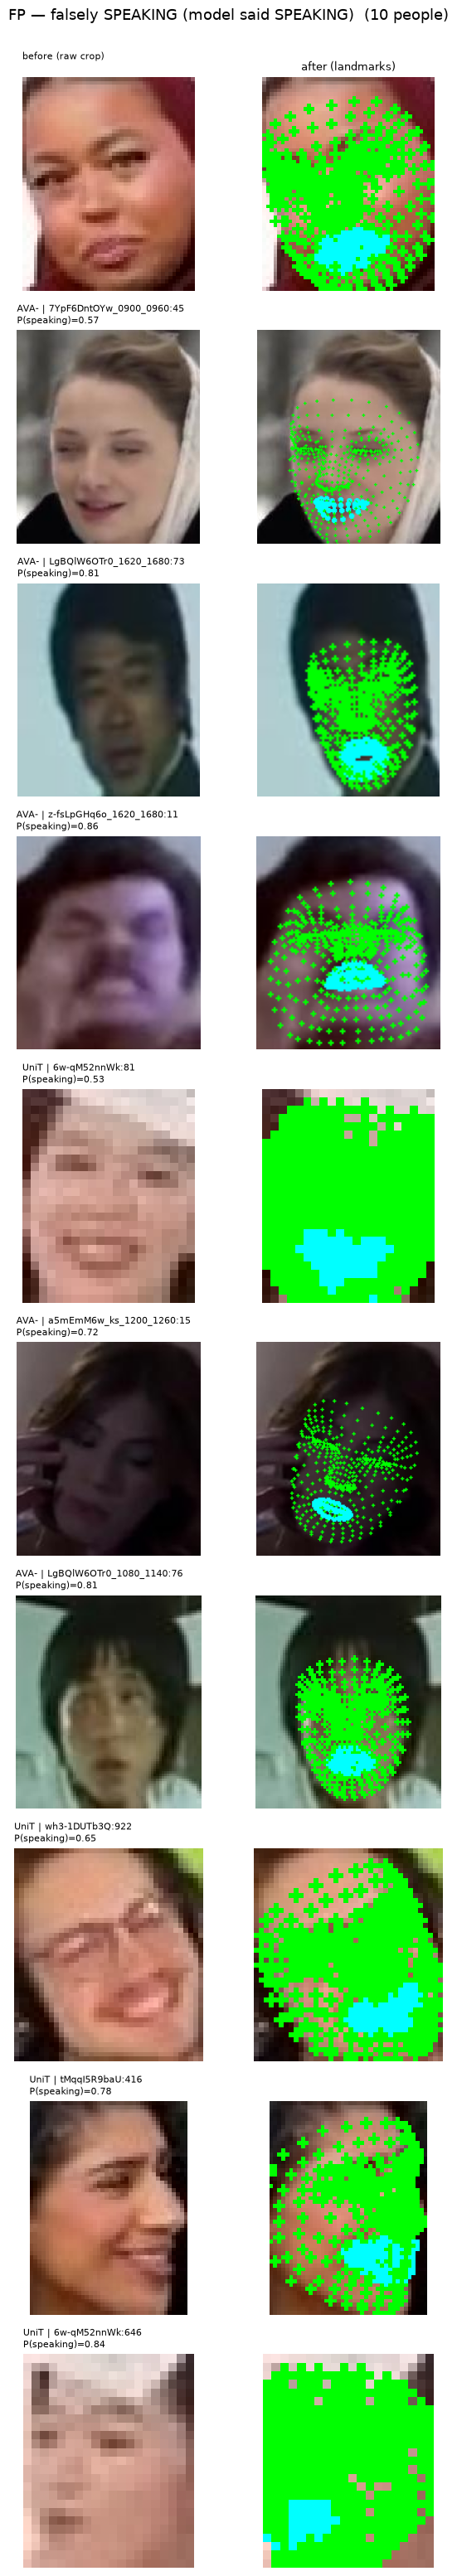

In [6]:
landmark_extractor = PersonLandmarkExtractor(normalize=False, save_annotated=False, save_json=False)
mouth_set = set(MOUTH_LANDMARK_INDICES)


def window_image_path(window: dict) -> Path:
    idx = representative_frame_index(window)
    image_name = window["image_names"][idx]
    return window["raw_dir"] / window["raw_split"] / window["video_id"] / window["person_id"] / image_name, window["detected"][idx]


def draw_landmarks(path: Path) -> tuple[Image.Image, bool]:
    from PIL import ImageDraw
    record = landmark_extractor.extract_image(path)
    img = Image.open(path).convert("RGB")
    if not record["detected"]:
        return img, False
    draw = ImageDraw.Draw(img)
    for i, (x, y, _z) in enumerate(record["face_landmarks"]):
        color = (0, 255, 255) if i in mouth_set else (0, 255, 0)
        r = 2 if i in mouth_set else 1
        draw.ellipse([x - r, y - r, x + r, y + r], fill=color)
    return img, True


def show_category(label: str, samples: list[dict]):
    n = len(samples)
    if n == 0:
        print(f"{label}: no examples found")
        return
    fig, axes = plt.subplots(n, 2, figsize=(6.4, 3.1 * n))
    if n == 1:
        axes = axes[np.newaxis, :]
    fig.suptitle(f"{label}  ({n} people)", fontsize=13, y=1.001)

    for r, w in enumerate(samples):
        path, was_detected_at_frame = window_image_path(w)
        before_ax, after_ax = axes[r, 0], axes[r, 1]
        before_ax.axis("off")
        after_ax.axis("off")
        if not path.exists():
            before_ax.set_title("(missing file)", fontsize=8)
            continue

        before_ax.imshow(Image.open(path).convert("RGB"))
        row_tag = f"{w['dataset'][:4]} | {w['person_id']}\nP(speaking)={w['prob']:.2f}"
        before_ax.set_title(row_tag, fontsize=8, loc="left")

        if was_detected_at_frame:
            img_after, redetected = draw_landmarks(path)
            after_ax.imshow(img_after)
            if not redetected:
                after_ax.set_title("(re-detect miss)", fontsize=8)
        else:
            after_ax.imshow(Image.open(path).convert("RGB"))
            after_ax.set_title("(no detected frame in window)", fontsize=8)

        if r == 0:
            before_ax.set_title("before (raw crop)\n" + before_ax.get_title(), fontsize=8, loc="left")
            after_ax.set_title("after (landmarks)", fontsize=9)

    fig.tight_layout()
    plt.show()


for label, samples in category_samples.items():
    show_category(label, samples)